# Solving the Traveling Salesman  Problem using Local Search

Points: 10

In [1]:
# --- Tự động lưu mọi hình vẽ ra thư mục figures/ (để chèn vào báo cáo) ---
import os, matplotlib.pyplot as plt
from IPython import get_ipython
os.makedirs("figures", exist_ok=True)
_FIG_PREFIX, _fig_n = "tsp", [0]
def _save_open_figs():
    for num in plt.get_fignums():
        fig = plt.figure(num)
        if getattr(fig, "_saved", False): continue
        _fig_n[0] += 1
        fig.savefig(f"figures/{_FIG_PREFIX}_{_fig_n[0]:02d}.png", dpi=150, bbox_inches="tight")
        fig._saved = True
_orig_show = plt.show
def _show(*a, **k):
    _save_open_figs(); return _orig_show(*a, **k)
plt.show = _show
_ip = get_ipython()
if _ip is not None:
    from matplotlib_inline import backend_inline
    try: _ip.events.unregister("post_execute", backend_inline.flush_figures)
    except Exception: pass
    def _flush():
        _save_open_figs(); backend_inline.flush_figures()
    _ip.events.register("post_execute", _flush)


## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)

In [3]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[2, 5, 7, 1, 9, 0, 4, 8, 6, 3]

In [4]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [5]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(4.33680280978909)

Tour length: 4.34


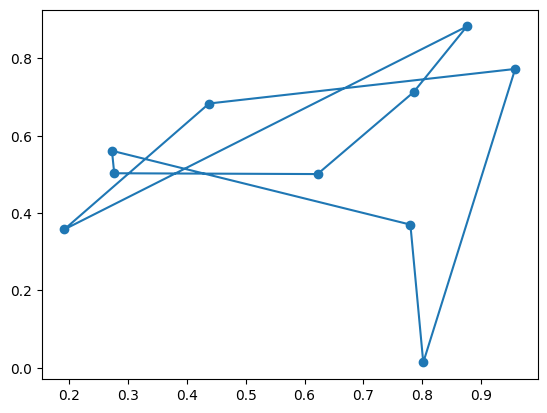

In [6]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (swap every pair of cities) and always choose the best among all local moves.

Tour ngẫu nhiên: 11.337  ->  steepest-ascent: 4.763  (10 bước, 2091 lần đánh giá)


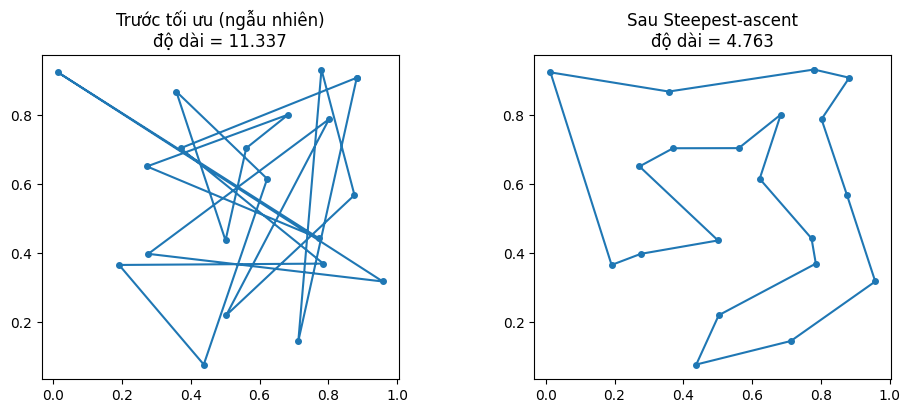

In [7]:
import time, math, itertools

SEED = 1234
random.seed(SEED); np.random.seed(SEED)

# Phiên bản tour_length vectorized (nhanh hơn, cho kết quả giống hệt tour_length ở trên) dùng trong các thuật toán
def tour_len(tsp, tour):
    t = np.asarray(tour)
    return float(tsp["dist"][t, np.roll(t, -1)].sum())

_t = random_tour(10)
assert abs(tour_len(tsp, _t) - tour_length(tsp, _t)) < 1e-9

# --- Toán tử lân cận dùng xuyên suốt: SWAP hai thành phố (cố định để so sánh thuật toán công bằng)
def swap(tour, i, j):
    t = list(tour); t[i], t[j] = t[j], t[i]; return t

def all_swaps(n):
    """Mọi cặp (i, j), i<j  ->  |N| = n(n-1)/2 láng giềng."""
    return [(i, j) for i in range(n - 1) for j in range(i + 1, n)]

def random_swap_pair(n):
    i, j = random.sample(range(n), 2)
    return (i, j) if i < j else (j, i)


def steepest_ascent_tsp(tsp, tour, max_steps=10_000):
    """Steepest-ascent (ở đây là steepest-DESCENT vì cực tiểu hoá độ dài): thử mọi phép swap, chọn phép tốt nhất."""
    tour = list(tour); n = len(tour)
    cur = tour_len(tsp, tour); evals = 1; hist = [cur]
    pairs = all_swaps(n)
    for _ in range(max_steps):
        best, best_len = None, cur
        for i, j in pairs:
            L = tour_len(tsp, swap(tour, i, j)); evals += 1
            if L < best_len - 1e-12:
                best, best_len = (i, j), L
        if best is None:                  # cực trị cục bộ theo toán tử swap
            break
        tour = swap(tour, *best); cur = best_len; hist.append(cur)
    return {"tour": tour, "length": cur, "evals": evals, "history": hist}

random.seed(SEED); np.random.seed(SEED)
tsp20 = random_tsp(20)
t0_tour = random_tour(20)
res = steepest_ascent_tsp(tsp20, t0_tour)
print(f"Tour ngẫu nhiên: {tour_len(tsp20, t0_tour):.3f}  ->  steepest-ascent: {res['length']:.3f}  ({len(res['history'])-1} bước, {res['evals']} lần đánh giá)")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, t, title in zip(ax, (t0_tour, res["tour"]), ("Trước tối ưu (ngẫu nhiên)", "Sau Steepest-ascent")):
    p = tsp20["pos"].reindex(t + [t[0]])
    a.plot(p["x"], p["y"], "-o", ms=4); a.set_title(f"{title}\nđộ dài = {tour_len(tsp20, t):.3f}"); a.set_aspect("equal")
plt.tight_layout(); plt.show()


**Mô tả (Steepest-ascent cho TSP).**
* *Trạng thái:* hoán vị các thành phố; *hàm mục tiêu:* độ dài chu trình khép kín `tour_length` (cực tiểu hoá, nên “leo dốc” ở đây là giảm độ dài).
* *Toán tử lân cận (cố định cho mọi thuật toán):* **swap** hai thành phố bất kỳ ⇒ |N| = n(n−1)/2 láng giềng (n = 20 → 190).
* Mỗi bước đánh giá cả 190 láng giềng và chọn tốt nhất; dừng khi không swap nào làm tour ngắn hơn (cực trị cục bộ). Bên dưới là tour trước/sau tối ưu: tour ngẫu nhiên dài ≈ 11.3 giảm còn ≈ 4.8 nhưng vẫn còn các cạnh bắt chéo – dấu hiệu kẹt ở cực trị cục bộ.
(Để nhanh hơn, các thuật toán dùng `tour_len` vector hoá; đã kiểm tra bằng `assert` rằng cho cùng kết quả với `tour_length` của đề.)

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

Một lần chạy ở trên: 4.763   |   Tốt nhất trong 20 restart: 4.139   (trung bình các lần: 4.734, tệ nhất: 5.148)


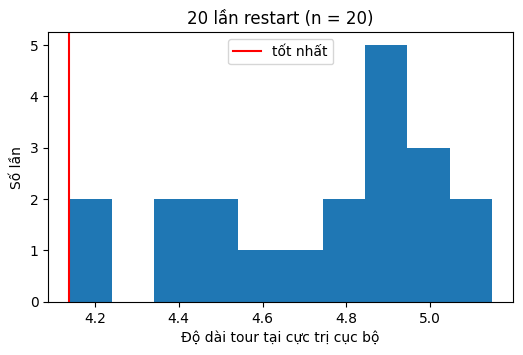

In [8]:
def random_restarts(tsp, algorithm, n_restarts=20, **kw):
    """Chạy `algorithm` từ n_restarts tour ngẫu nhiên khác nhau, giữ tour ngắn nhất."""
    n = len(tsp["dist"]); best = None; evals = 0; lengths = []
    for _ in range(n_restarts):
        r = algorithm(tsp, random_tour(n), **kw)
        evals += r["evals"]; lengths.append(r["length"])
        if best is None or r["length"] < best["length"]: best = r
    return {**best, "evals": evals, "all_lengths": lengths}

random.seed(SEED); np.random.seed(SEED)
rr = random_restarts(tsp20, steepest_ascent_tsp, n_restarts=20)
print(f"Một lần chạy ở trên: {res['length']:.3f}   |   Tốt nhất trong 20 restart: {rr['length']:.3f}   "
      f"(trung bình các lần: {np.mean(rr['all_lengths']):.3f}, tệ nhất: {np.max(rr['all_lengths']):.3f})")
plt.figure(figsize=(6, 3.5)); plt.hist(rr["all_lengths"], bins=10); plt.axvline(rr["length"], color="r", label="tốt nhất")
plt.xlabel("Độ dài tour tại cực trị cục bộ"); plt.ylabel("Số lần"); plt.title("20 lần restart (n = 20)"); plt.legend(); plt.show()


**Nhận xét (Random Restart).** Các lần chạy steepest-ascent kết thúc ở những cực trị cục bộ rất khác nhau (tour dài ~4.1 đến ~5.1). Giữ tour tốt nhất trong 20 lần restart cho ≈ 4.14, tốt hơn rõ rệt một lần chạy đơn (≈ 4.76) – nhưng chi phí nhân với 20.

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

In [9]:
def stochastic_hc_tsp(tsp, tour, max_steps=10_000):
    """Stochastic hill climbing: liệt kê MỌI swap cải thiện rồi chọn ngẫu nhiên một cái."""
    tour = list(tour); n = len(tour)
    cur = tour_len(tsp, tour); evals = 1; hist = [cur]
    pairs = all_swaps(n)
    for _ in range(max_steps):
        better = []
        for i, j in pairs:
            L = tour_len(tsp, swap(tour, i, j)); evals += 1
            if L < cur - 1e-12: better.append((i, j, L))
        if not better: break
        i, j, cur = random.choice(better)
        tour = swap(tour, i, j); hist.append(cur)
    return {"tour": tour, "length": cur, "evals": evals, "history": hist}

random.seed(SEED)
r = stochastic_hc_tsp(tsp20, t0_tour)
print(f"Stochastic HC: {tour_len(tsp20, t0_tour):.3f} -> {r['length']:.3f}  ({len(r['history'])-1} bước, {r['evals']} lần đánh giá)")


Stochastic HC: 11.337 -> 5.042  (28 bước, 5511 lần đánh giá)


**Nhận xét (Stochastic HC – chọn ngẫu nhiên trong các swap cải thiện).** Mỗi bước vẫn phải đánh giá toàn bộ láng giềng (tốn như steepest) nhưng đi những bước nhỏ hơn nên cần nhiều bước hơn (28 so với 10) và tổng số lần đánh giá lớn hơn (~5.5k so với ~2.1k); chất lượng tương đương hoặc hơi kém vì không ưu tiên bước tốt nhất.

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

In [10]:
def first_choice_tsp(tsp, tour, c=2.0, max_iter=200_000):
    """First-choice HC: sinh MỘT swap ngẫu nhiên, nhận nếu ngắn hơn.
    Dừng nếu m(ln m + c) lần thử liên tiếp không cải thiện (m = n(n-1)/2, xem lập luận coupon collector ở bài n-Queens)."""
    tour = list(tour); n = len(tour)
    m = n * (n - 1) // 2
    patience = int(math.ceil(m * (math.log(m) + c)))
    cur = tour_len(tsp, tour); evals = 1; fails = 0; hist = [cur]
    for _ in range(max_iter):
        i, j = random_swap_pair(n)
        L = tour_len(tsp, swap(tour, i, j)); evals += 1
        if L < cur - 1e-12: tour = swap(tour, i, j); cur = L; fails = 0
        else: fails += 1
        hist.append(cur)
        if fails >= patience: break
    return {"tour": tour, "length": cur, "evals": evals, "history": hist}

random.seed(SEED)
r = first_choice_tsp(tsp20, t0_tour)
print(f"First-choice HC: {tour_len(tsp20, t0_tour):.3f} -> {r['length']:.3f}  ({r['evals']} lần đánh giá)")


First-choice HC: 11.337 -> 5.261  (2654 lần đánh giá)


**Nhận xét (First-choice HC).** Mỗi lần chỉ đánh giá 1 láng giềng ngẫu nhiên; tiêu chí dừng dùng cùng lập luận coupon-collector như n-Queens (m = n(n−1)/2). Rẻ nhất mỗi vòng nhưng, giống các biến thể khác, vẫn dừng ở cực trị cục bộ theo toán tử swap.

## Simulated Annealing [2 Points]

SA: 11.337 -> 4.025


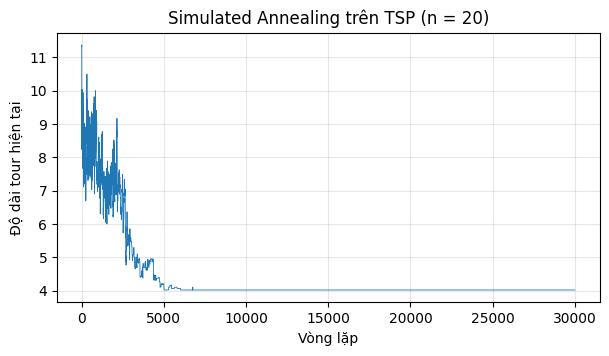

Tour length: 4.02


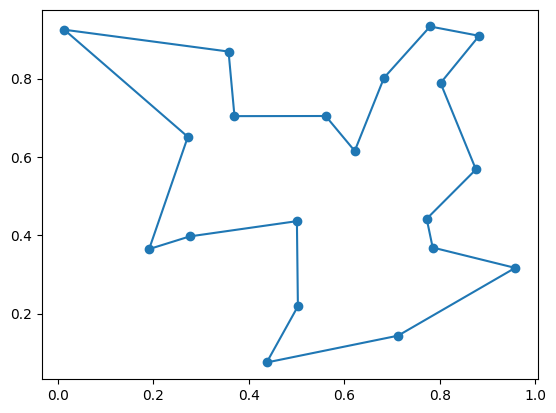

In [11]:
def simulated_annealing_tsp(tsp, tour, T0=0.5, alpha=0.9995, max_iter=30_000):
    """SA với lịch mũ T(t) = T0 * alpha^t và toán tử swap. Δ>0 được nhận với xác suất exp(-Δ/T).
    T0 ~ cỡ chênh lệch độ dài điển hình của một swap trong hình vuông 1x1 (khoảng 0.1–1)."""
    tour = list(tour); n = len(tour)
    cur = tour_len(tsp, tour); best, best_len = tour[:], cur
    evals = 1; hist = [cur]
    for t in range(1, max_iter + 1):
        T = T0 * alpha ** t
        i, j = random_swap_pair(n)
        cand = swap(tour, i, j); L = tour_len(tsp, cand); evals += 1
        d = L - cur
        if d < 0 or random.random() < math.exp(-d / max(T, 1e-12)):
            tour, cur = cand, L
            if cur < best_len: best, best_len = tour[:], cur
        hist.append(cur)
    return {"tour": best, "length": best_len, "evals": evals, "history": hist}

random.seed(SEED)
r_sa = simulated_annealing_tsp(tsp20, t0_tour)
print(f"SA: {tour_len(tsp20, t0_tour):.3f} -> {r_sa['length']:.3f}")
plt.figure(figsize=(7, 3.5)); plt.plot(r_sa["history"], lw=.6); plt.xlabel("Vòng lặp"); plt.ylabel("Độ dài tour hiện tại")
plt.title("Simulated Annealing trên TSP (n = 20)"); plt.grid(alpha=.3); plt.show()
show_tsp(tsp20, r_sa["tour"])


**Nhận xét (Simulated Annealing).** Lịch mũ T(t) = T₀·αᵗ với T₀ = 0.5, α = 0.9995, 30 000 vòng. Độ dài tour hiện tại dao động mạnh ở giai đoạn đầu (chấp nhận bước xấu) rồi giảm và ổn định. Với cùng toán tử swap, SA cho tour ngắn nhất trong các lần chạy mẫu (≈ 4.0 so với ≈ 4.7–5.3 của các Hill Climbing đơn lẻ).

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [12]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.1270771026611328 milliseconds


Độ dài tối ưu (vét cạn, n=9) = 2.7772


,Tốt nhất,Trung bình,Thời gian (ms),Cải thiện so với tour đầu (%),Cách tối ưu (%)
Steepest-ascent,2.78,2.84,1.89,33.19,0.0
Stochastic HC (all),2.78,2.83,3.07,34.91,0.0
First-choice HC,2.78,2.84,3.81,34.45,0.0
Steepest + 20 restarts,2.78,2.78,37.11,36.32,0.0
Simulated Annealing,2.78,2.78,460.56,35.43,0.0


Độ dài tour TB,10,20,30,50
Thuật toán,,,,
First-choice HC,3.39,4.69,5.50,8.81
Simulated Annealing,3.39,4.30,5.12,7.51
Steepest + 20 restarts,3.39,4.11,4.77,7.27
Steepest-ascent,3.39,4.72,5.64,8.42
Stochastic HC (all),3.39,4.76,5.86,8.83


Thời gian TB (ms),10,20,30,50
Thuật toán,,,,
First-choice HC,7.8,33.3,110.8,333.0
Simulated Annealing,431.4,449.4,467.2,475.5
Steepest + 20 restarts,68.2,617.3,2707.2,15360.6
Steepest-ascent,3.4,30.0,120.0,800.3
Stochastic HC (all),5.6,66.5,347.9,1903.4


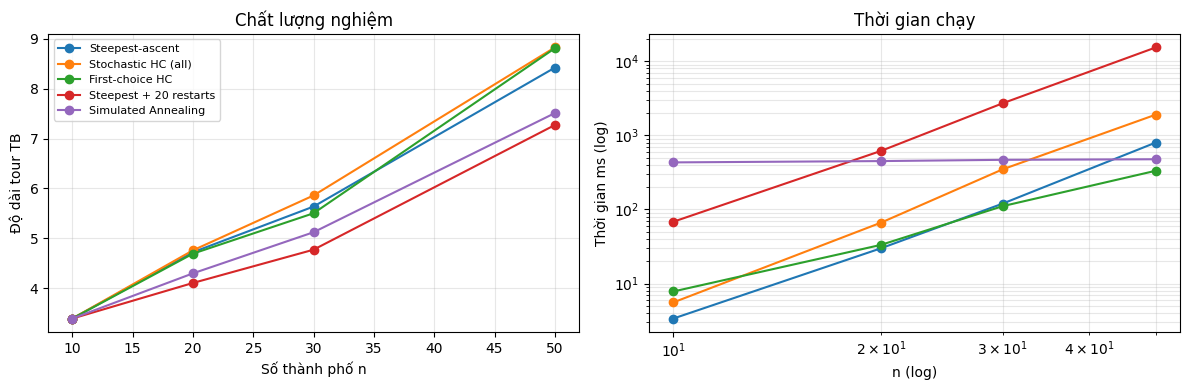

,swap,2-opt
TB,5.80,4.87
Tốt nhất,4.94,4.65
Độ lệch chuẩn,0.43,0.09


In [13]:
# 1) Độ chính xác: so với nghiệm TỐI ƯU (vét cạn) trên bài nhỏ n = 9
random.seed(SEED); np.random.seed(SEED)
tsp9 = random_tsp(9)
opt = min(tour_len(tsp9, (0,) + p) for p in itertools.permutations(range(1, 9)))
print(f"Độ dài tối ưu (vét cạn, n=9) = {opt:.4f}")

algos = {
    "Steepest-ascent":        lambda tsp, t: steepest_ascent_tsp(tsp, t),
    "Stochastic HC (all)":    lambda tsp, t: stochastic_hc_tsp(tsp, t),
    "First-choice HC":        lambda tsp, t: first_choice_tsp(tsp, t),
    "Steepest + 20 restarts": lambda tsp, t: random_restarts(tsp, steepest_ascent_tsp, 20),
    "Simulated Annealing":    lambda tsp, t: simulated_annealing_tsp(tsp, t),
}
def bench(tsp, runs=10, seed=SEED):
    n = len(tsp["dist"]); random.seed(seed); out = {}
    for name, alg in algos.items():
        L, T, I = [], [], []
        for _ in range(runs):
            t0 = random_tour(n); init = tour_len(tsp, t0)
            s = time.perf_counter(); r = alg(tsp, t0); T.append((time.perf_counter() - s) * 1e3)
            L.append(r["length"]); I.append(1 - r["length"] / init)
        out[name] = dict(best=min(L), mean=np.mean(L), time_ms=np.mean(T), improve=100 * np.mean(I))
    return out

b9 = bench(tsp9, runs=20)
display(pd.DataFrame(b9).T.assign(gap_pct=lambda d: 100 * (d["best"] / opt - 1)).round(3)
        .rename(columns={"best": "Tốt nhất", "mean": "Trung bình", "time_ms": "Thời gian (ms)", "improve": "Cải thiện so với tour đầu (%)", "gap_pct": "Cách tối ưu (%)"}))

# 2) Khả năng mở rộng theo số thành phố
rows = []
for n in (10, 20, 30, 50):
    random.seed(SEED + n); np.random.seed(SEED + n)
    tsp_n = random_tsp(n)
    for name, v in bench(tsp_n, runs=5).items():
        rows.append({"n": n, "Thuật toán": name, **v})
sc = pd.DataFrame(rows)
display(sc.pivot(index="Thuật toán", columns="n", values="mean").round(3).rename_axis(columns="Độ dài tour TB"))
display(sc.pivot(index="Thuật toán", columns="n", values="time_ms").round(1).rename_axis(columns="Thời gian TB (ms)"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in algos:
    d = sc[sc["Thuật toán"] == name]
    ax[0].plot(d.n, d["mean"], "o-", label=name); ax[1].loglog(d.n, d.time_ms, "o-", label=name)
ax[0].set_xlabel("Số thành phố n"); ax[0].set_ylabel("Độ dài tour TB"); ax[0].set_title("Chất lượng nghiệm"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].set_xlabel("n (log)"); ax[1].set_ylabel("Thời gian ms (log)"); ax[1].set_title("Thời gian chạy"); ax[1].grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()

# 3) Ảnh hưởng của toán tử lân cận: swap vs 2-opt (đảo đoạn) bằng first-choice HC, n = 30
def two_opt(tour, i, j):
    t = list(tour); t[i:j + 1] = reversed(t[i:j + 1]); return t

def first_choice_op(tsp, tour, move, c=2.0):
    tour = list(tour); n = len(tour); m = n * (n - 1) // 2
    patience = int(math.ceil(m * (math.log(m) + c))); cur = tour_len(tsp, tour); fails = 0
    while fails < patience:
        i, j = random_swap_pair(n); cand = move(tour, i, j); L = tour_len(tsp, cand)
        if L < cur - 1e-12: tour, cur, fails = cand, L, 0
        else: fails += 1
    return tour, cur

random.seed(SEED); np.random.seed(SEED)
tsp30 = random_tsp(30)
res_op = {}
for name, mv in (("swap", swap), ("2-opt", two_opt)):
    random.seed(SEED)
    res_op[name] = [first_choice_op(tsp30, random_tour(30), mv)[1] for _ in range(20)]
display(pd.DataFrame({k: [np.mean(v), np.min(v), np.std(v)] for k, v in res_op.items()}, index=["TB", "Tốt nhất", "Độ lệch chuẩn"]).round(3))


**Phân tích so sánh.**
* **Độ chính xác (n = 9, có nghiệm tối ưu bằng vét cạn = 2.777):** mọi thuật toán đều *tìm được* tour tối ưu ít nhất một lần trong 20 lần chạy, nhưng chỉ SA và Steepest + restart có *trung bình* đúng tối ưu (2.78) – các Hill Climbing đơn lẻ trung bình lệch ~2% (2.83–2.84) do hay kẹt.
* **Mở rộng theo n (10 → 50 thành phố):** chất lượng tour trung bình: Steepest + 20 restart tốt nhất (n=50: 7.27), rồi SA (7.51), steepest (8.42), First-choice (8.81), Stochastic-all (8.83). Hill Climbing đơn lẻ kém dần khi n tăng vì số cực trị cục bộ tăng nhanh.
* **Thời gian:** First-choice và steepest nhanh nhất ở n nhỏ; Stochastic-all và Steepest + restart tăng rất nhanh theo n (n=50: ~1.9 s và ~15 s) do mỗi bước phải duyệt O(n²) láng giềng. SA có ngân sách cố định (30 000 vòng) nên thời gian gần như không đổi (~0.4 s) – với n lớn SA là lựa chọn **cân bằng nhất giữa chất lượng và thời gian** (kém restart 3%, nhanh gấp ~30 lần).
* **Toán tử lân cận (câu thảo luận 10):** thay swap bằng **2-opt** (đảo một đoạn, loại bỏ các cạnh bắt chéo), First-choice HC trên n = 30 cải thiện từ độ dài TB 5.80 xuống 4.87 và ổn định hơn nhiều (độ lệch chuẩn 0.43 → 0.09). Swap đổi 4 cạnh một lúc nên “bước” thô; 2-opt chỉ đổi 2 cạnh, phù hợp cấu trúc hình học của TSP nên cực trị cục bộ của nó tốt hơn. Số láng giềng của cả hai đều cỡ n(n−1)/2 nhưng chất lượng khác biệt: **chất lượng toán tử quan trọng hơn kích thước lân cận**.
* **Hạn chế:** cả hai toán tử đều chỉ tìm cục bộ; không có bảo đảm tối ưu toàn cục (ngoại trừ SA với lịch logarithmic ở giới hạn vô hạn). Kết quả dựa trên ít lần chạy ở n lớn (5 lần) nên có nhiễu.

## Bonus: Genetic Algorithm [+1 Point]

In [14]:
def genetic_algorithm_tsp(tsp, pop_size=100, generations=300, p_mut=0.2, elite=2):
    """GA đơn giản: chọn lọc giải đấu, lai ghép thứ tự (OX), đột biến swap, giữ lại `elite` cá thể tốt nhất."""
    n = len(tsp["dist"])
    pop = [random_tour(n) for _ in range(pop_size)]
    def ox(a, b):
        i, j = sorted(random.sample(range(n), 2)); child = [None] * n; child[i:j] = a[i:j]
        rest = [c for c in b if c not in child[i:j]]; k = 0
        for x in range(n):
            if child[x] is None: child[x] = rest[k]; k += 1
        return child
    best = min(pop, key=lambda t: tour_len(tsp, t))
    for _ in range(generations):
        fit = [tour_len(tsp, t) for t in pop]
        order = np.argsort(fit); new = [pop[k] for k in order[:elite]]
        while len(new) < pop_size:
            pa = min(random.sample(range(pop_size), 3), key=lambda k: fit[k]); pb = min(random.sample(range(pop_size), 3), key=lambda k: fit[k])
            child = ox(pop[pa], pop[pb])
            if random.random() < p_mut: i, j = random_swap_pair(n); child = swap(child, i, j)
            new.append(child)
        pop = new
        cand = min(pop, key=lambda t: tour_len(tsp, t))
        if tour_len(tsp, cand) < tour_len(tsp, best): best = cand
    return {"tour": best, "length": tour_len(tsp, best)}

random.seed(SEED)
ga = genetic_algorithm_tsp(tsp20)
print(f"Genetic Algorithm (n=20): {ga['length']:.3f}   vs   SA: {r_sa['length']:.3f}   vs   Steepest + restarts: {rr['length']:.3f}")


Genetic Algorithm (n=20): 4.506   vs   SA: 4.025   vs   Steepest + restarts: 4.139


**Bonus – Genetic Algorithm.** Với n = 20, GA đơn giản (quần thể 100, 300 thế hệ, lai OX, đột biến swap) cho ≈ 4.5: tốt hơn Hill Climbing đơn lẻ nhưng kém SA/restart trong cấu hình này; chưa tinh chỉnh tham số.